# 01 - EDA baseline: audit of the modelling dataset

**Role:** ZM - EDA and statistical analysis
**Deliverable:** `notebooks/01_eda.ipynb`, step 1 of the EDA work
**Scope of this step:** load the dataset through the official team chain and audit it.

This notebook performs **no imputation, no encoding, no scaling, no feature
selection and no statistical test**. It only describes the data as it is, so that
every later analysis starts from a frozen, verifiable baseline.

## Provenance note

- **Dataset version:** the file currently available at commit **`bd8a0cb`**
  (`data: add filtered dataset without ISR in data/raw`).
- **File used:** `data/raw/startup_data.csv`, 14 columns, Kaggle *Big Startup
  Success/Fail Dataset from Crunchbase*.
- **965 Israeli records removed:** the current file contains no row with
  `country_code = "ISR"`. The already-filtered files were committed in `91a6a04`
  (`data/processed/`) and `bd8a0cb` (`data/raw/`); the removal itself is not
  visible in Git because the pre-filter file was never committed. The pre-filter
  file used by TAS in notebook 02 (executed 2026-10-31) had 66,368 rows; the
  committed file has 65,403, and the four status counts differ by exactly 965
  (operating -760, closed -77, acquired -86, ipo -42). **This removal is awaiting
  confirmation** from TAS / the repository owner and is not yet documented in the
  project docs.
- **Raw and processed copies are identical:** `data/processed/startup_data_no_isr.csv`
  is byte-for-byte the same file as `data/raw/startup_data.csv` (checked below),
  and no code reads the processed copy.
- **Documentation is out of date:** `docs/handoff_preprocessing.md` and
  `docs/methodology.md` still quote 66,368 raw rows and 13,334 target rows. The
  figures verified here are **65,403** and **13,129**.

All reported figures are computed at execution time; the four expected counts are
hard-coded on purpose as assertions.


## 0. Setup

The notebook lives in `notebooks/`, while the modules live in `src/` and the data
in `data/`. The cell below locates the repository root, imports the **official
team modules** (never re-implementing them), and sets display options.

Only `data_loader`, `features` and `targets` are imported at this stage:
`preprocessing` is deliberately excluded because this step must not transform
anything.


In [1]:
from pathlib import Path
import hashlib
import subprocess
import sys

import pandas as pd
from IPython.display import display

# The notebook lives in notebooks/; src/ and data/ live at the repository root.
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import data_loader
import features
import targets

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 120)

DATA_PATH = ROOT / "data" / "raw" / "startup_data.csv"
PROCESSED_PATH = ROOT / "data" / "processed" / "startup_data_no_isr.csv"

print("Repository root :", ROOT)
print("Dataset         :", DATA_PATH.relative_to(ROOT), f"({DATA_PATH.stat().st_size / 1e6:.1f} MB)")
print("data_loader     :", Path(data_loader.__file__).relative_to(ROOT))
print("features        :", Path(features.__file__).relative_to(ROOT))
print("targets         :", Path(targets.__file__).relative_to(ROOT))

Repository root : F:\Project FDD
Dataset         : data\raw\startup_data.csv (10.8 MB)
data_loader     : src\data_loader.py
features        : src\features.py
targets         : src\targets.py


### 0.1 Provenance evidence

Two facts are checked rather than asserted in prose: the commit the notebook is
executed on, and whether the "processed" copy really is a duplicate of the raw one.


In [2]:
head = subprocess.run(
    ["git", "rev-parse", "--short", "HEAD"],
    cwd=ROOT,
    capture_output=True,
    text=True,
    check=True,
).stdout.strip()

sha_raw = hashlib.sha1(DATA_PATH.read_bytes()).hexdigest()
sha_processed = hashlib.sha1(PROCESSED_PATH.read_bytes()).hexdigest()

print(f"Current HEAD           : {head}")
print(f"Documented base commit : bd8a0cb")
print(f"SHA-1 data/raw/        : {sha_raw}")
print(f"SHA-1 data/processed/  : {sha_processed}")
print(f"Raw and processed are byte-identical: {sha_raw == sha_processed}")

Current HEAD           : 2b03a39
Documented base commit : bd8a0cb
SHA-1 data/raw/        : 1d425a91c0cf1f2513c243ce426dd3ffa5f07932
SHA-1 data/processed/  : 1d425a91c0cf1f2513c243ce426dd3ffa5f07932
Raw and processed are byte-identical: True


## 1. Loading through the official chain

The dataset is built by calling the team functions in the order defined in
`docs/handoff_preprocessing.md`:

1. `data_loader.load_raw()` - reads the CSV, strips column names, filters nothing.
2. `features.build_features(max_year=2026)` - cleans the four geographic columns
   (`country_code`, `state_code`, `region`, `city`), derives `primary_category`
   and `founding_year`, and adds `founding_month`, which is EDA-only. Together
   these are the six protocol features.
3. `targets.prepare_target()` - keeps `ipo`, `acquired`, `closed`, drops
   `operating`, and creates the binary `target`.

Nothing is imputed, encoded or scaled here.


In [3]:
raw = data_loader.load_raw(DATA_PATH)
with_features = features.build_features(raw, max_year=2026)
dataset = targets.prepare_target(with_features)

print(f"load_raw        : {raw.shape[0]:>6,} rows x {raw.shape[1]:>2} columns")
print(f"build_features  : {with_features.shape[0]:>6,} rows x {with_features.shape[1]:>2} columns")
print(f"prepare_target  : {dataset.shape[0]:>6,} rows x {dataset.shape[1]:>2} columns")

load_raw        : 65,403 rows x 14 columns
build_features  : 65,403 rows x 17 columns
prepare_target  : 13,129 rows x 18 columns


### 1.1 Verification of the expected counts

These four numbers are the contract of this deliverable. If any of them changes,
the notebook **stops with an explicit error** instead of continuing with a
different dataset: that would mean the data or the team code changed, and the
figures in the report would no longer be comparable.


In [4]:
EXPECTED_RAW_ROWS = 65_403
EXPECTED_TARGET_ROWS = 13_129
EXPECTED_SUCCESS = 6_968
EXPECTED_FAILURE = 6_161

target_counts = dataset["target"].value_counts().sort_index()
success = int(target_counts.get(1, 0))
failure = int(target_counts.get(0, 0))

assert raw.shape[0] == EXPECTED_RAW_ROWS, (
    f"Raw row count changed: {raw.shape[0]:,} != {EXPECTED_RAW_ROWS:,}"
)
assert dataset.shape[0] == EXPECTED_TARGET_ROWS, (
    f"Target-prepared row count changed: {dataset.shape[0]:,} != {EXPECTED_TARGET_ROWS:,}"
)
assert success == EXPECTED_SUCCESS, (
    f"Success count changed: {success:,} != {EXPECTED_SUCCESS:,}"
)
assert failure == EXPECTED_FAILURE, (
    f"Failure count changed: {failure:,} != {EXPECTED_FAILURE:,}"
)

verification = pd.DataFrame(
    [
        ("raw rows", raw.shape[0], EXPECTED_RAW_ROWS),
        ("target-prepared rows", dataset.shape[0], EXPECTED_TARGET_ROWS),
        ("success (target = 1)", success, EXPECTED_SUCCESS),
        ("failure (target = 0)", failure, EXPECTED_FAILURE),
    ],
    columns=["check", "observed", "expected"],
)
verification["match"] = verification["observed"] == verification["expected"]
display(verification)
print("All four expected counts match.")

,check,observed,expected,match
0,raw rows,65403,65403,True
1,target-prepared rows,13129,13129,True
2,success (target = 1),6968,6968,True
3,failure (target = 0),6161,6161,True


All four expected counts match.


## 2. Dataset dimensions

Row and column counts at each stage of the chain. The row count only changes at
`prepare_target` (exclusion of `operating`); the column count grows by three
derived columns (`primary_category`, `founding_year`, `founding_month`) and
`target` (14 -> 17 -> 18).


In [5]:
dimensions = pd.DataFrame(
    [
        ("raw (data_loader.load_raw)", *raw.shape),
        ("+ features (features.build_features)", *with_features.shape),
        ("+ target (targets.prepare_target)", *dataset.shape),
    ],
    columns=["stage", "rows", "columns"],
)
display(dimensions)

,stage,rows,columns
0,raw (data_loader.load_raw),65403,14
1,+ features (features.build_features),65403,17
2,+ target (targets.prepare_target),13129,18


## 3. Columns and data types

The raw file has 14 columns, all stored as text except `funding_rounds`. The
chain adds derived columns; their types matter because `founding_year` is a
`float64` (so that scikit-learn can impute it later) while the categorical
features stay nullable text.

`funding_total_usd` is text rather than numeric because Crunchbase uses `"-"` as
a missing marker.


In [6]:
raw_dtypes = raw.dtypes.astype(str).to_frame("dtype")
raw_dtypes.index.name = "column"
print(f"Raw columns ({raw.shape[1]}):")
display(raw_dtypes)

added_features = [column for column in with_features.columns if column not in raw.columns]
added_target = [column for column in dataset.columns if column not in with_features.columns]
print("Added by features.build_features :", added_features)
print("Added by targets.prepare_target :", added_target)

final_dtypes = dataset.dtypes.astype(str).to_frame("dtype")
final_dtypes.index.name = "column"
print(f"\nTarget-prepared columns ({dataset.shape[1]}):")
display(final_dtypes)

Raw columns (14):


,dtype
column,
permalink,object
name,object
homepage_url,object
category_list,object
funding_total_usd,object
status,object
country_code,object
state_code,object
region,object


Added by features.build_features : ['primary_category', 'founding_year', 'founding_month']
Added by targets.prepare_target : ['target']

Target-prepared columns (18):


,dtype
column,
permalink,object
name,object
homepage_url,object
category_list,object
funding_total_usd,object
status,string
country_code,string
state_code,string
region,string


## 4. Target distribution

`target = 1` groups IPO and acquisition (success under the project convention),
`target = 0` is closure. `operating` is excluded, which is why the target-prepared
set is much smaller than the raw file.

The class balance is close to 50/50, so no resampling is required at this stage.


In [7]:
target_distribution = pd.DataFrame(
    {
        "rows": target_counts,
        "share (%)": (100 * target_counts / len(dataset)).round(2),
    }
)
target_distribution.index = ["0 - failure (closed)", "1 - success (ipo / acquired)"]
display(target_distribution)

raw_status = raw["status"].value_counts().to_frame("rows")
raw_status["share (%)"] = (100 * raw_status["rows"] / len(raw)).round(1)
print("Raw status distribution (before exclusion of operating):")
display(raw_status)

print("Status vs target in the target-prepared dataset:")
display(pd.crosstab(dataset["status"], dataset["target"], margins=True, margins_name="total"))

,rows,share (%)
0 - failure (closed),6161,46.93
1 - success (ipo / acquired),6968,53.07


Raw status distribution (before exclusion of operating):


,rows,share (%)
status,,
operating,52274,79.9
closed,6161,9.4
acquired,5463,8.4
ipo,1505,2.3


Status vs target in the target-prepared dataset:


target,0,1,total
status,,,
acquired,0,5463,5463
closed,6161,0,6161
ipo,0,1505,1505
total,6161,6968,13129


## 5. Missing values

Counts and percentages are reported on the raw file and on the target-prepared
file. **No value is filled here**: imputation belongs to
`src/preprocessing.py` pipelines, learned on the training set only.

The last table restricts the view to the six protocol features, because those are
the columns the models will actually consume.


In [8]:
def missing_table(frame: pd.DataFrame) -> pd.DataFrame:
    counts = frame.isna().sum()
    table = pd.DataFrame(
        {
            "column": counts.index,
            "missing": counts.to_numpy(),
            "share (%)": (100 * counts.to_numpy() / len(frame)).round(1),
        }
    )
    table = table[table["missing"] > 0].sort_values("missing", ascending=False)
    return table.reset_index(drop=True)

print(f"Raw dataset - {len(raw):,} rows")
display(missing_table(raw))

print(f"Target-prepared dataset - {len(dataset):,} rows")
display(missing_table(dataset))

protocol_missing = pd.DataFrame(
    {
        "column": list(features.FEATURE_COLUMNS),
        "missing": [int(dataset[column].isna().sum()) for column in features.FEATURE_COLUMNS],
    }
)
protocol_missing["share (%)"] = (100 * protocol_missing["missing"] / len(dataset)).round(1)
print("Missing values among the six protocol features:")
display(protocol_missing)

Raw dataset - 65,403 rows


,column,missing,share (%)
0,founded_at,15089,23.1
1,state_code,8447,12.9
2,region,7928,12.1
3,city,7926,12.1
4,country_code,6958,10.6
5,homepage_url,5018,7.7
6,category_list,3126,4.8
7,first_funding_at,23,0.0
8,name,1,0.0


Target-prepared dataset - 13,129 rows


,column,missing,share (%)
0,founding_month,3719,28.3
1,founding_year,3719,28.3
2,founded_at,3698,28.2
3,state_code,2190,16.7
4,city,2133,16.2
5,region,2133,16.2
6,country_code,1991,15.2
7,homepage_url,1209,9.2
8,primary_category,1077,8.2
9,category_list,1077,8.2


Missing values among the six protocol features:


,column,missing,share (%)
0,country_code,1991,15.2
1,state_code,2190,16.7
2,region,2133,16.2
3,city,2133,16.2
4,primary_category,1077,8.2
5,founding_year,3719,28.3


## 6. Duplicate checks

Three levels are checked: fully duplicated rows, duplicated `permalink` (the
Crunchbase identifier) and duplicated `name`.

A duplicated name is **not** necessarily an error: different companies can share a
name. It is reported for information, not as a defect to fix in this step.


In [9]:
duplicates = pd.DataFrame(
    [
        (
            "exact duplicate rows",
            int(raw.duplicated().sum()),
            int(dataset.duplicated().sum()),
        ),
        (
            "duplicate permalink",
            int(raw["permalink"].duplicated().sum()),
            int(dataset["permalink"].duplicated().sum()),
        ),
        (
            "duplicate name",
            int(raw["name"].duplicated().sum()),
            int(dataset["name"].duplicated().sum()),
        ),
    ],
    columns=["check", "raw", "target-prepared"],
)
display(duplicates)

,check,raw,target-prepared
0,exact duplicate rows,0,0
1,duplicate permalink,0,0
2,duplicate name,262,8


## 7. Founding year: range and missing values

`founding_year` comes from `features.split_founded_at`, which masks dates that
cannot be parsed or fall outside pandas' timestamp range, as well as implausible
years (before 1900 or after `max_year=2026`). `founded_at` itself keeps the
original text, so the two columns do not necessarily report the same number of
missing values: a non-null `founded_at` can still yield a missing `founding_year`
when its date is rejected.

This matters for the Mann-Whitney test planned in the next step: more than a
quarter of the target-prepared rows have no usable founding year.


In [10]:
founding_year = dataset["founding_year"]
founded_dates = pd.to_datetime(dataset["founded_at"], errors="coerce", format="mixed")
raw_years = pd.to_datetime(raw["founded_at"], errors="coerce", format="mixed").dt.year

founding_summary = pd.DataFrame(
    [
        ("rows", f"{len(dataset):,}"),
        ("founding_year present", f"{int(founding_year.notna().sum()):,}"),
        ("founding_year missing", f"{int(founding_year.isna().sum()):,}"),
        ("missing share (%)", f"{100 * founding_year.isna().mean():.1f}"),
        ("min", f"{founding_year.min():.0f}"),
        ("max", f"{founding_year.max():.0f}"),
        ("median", f"{founding_year.median():.0f}"),
    ],
    columns=["metric", "value"],
)
display(founding_summary)

# Decades are built from founding_year (plausibility mask applied), not from the
# raw text, so implausible dates are not counted twice.
decades = (founding_year // 10 * 10).value_counts().sort_index()
decades.index = decades.index.astype(int)
print("Rows with a usable founding_year, per decade:")
display(decades.rename_axis("decade").to_frame("rows"))

print("Raw founded_at missing                         :", f"{int(raw['founded_at'].isna().sum()):,}")
print("Raw founded_at before 1900 (masked by features):", f"{int((raw_years < 1900).sum()):,}")
print("Raw founded_at after 2026  (masked by features):", f"{int((raw_years > 2026).sum()):,}")
print("Raw founded_at out-of-range/unparseable (masked):", f"{int(raw_years.isna().sum() - raw['founded_at'].isna().sum()):,}")
print("Labeled founded_at before 1900 (masked)        :", f"{int((founded_dates.dt.year < 1900).sum()):,}")
print("Labeled founded_at after 2026  (masked)        :", f"{int((founded_dates.dt.year > 2026).sum()):,}")
print("Labeled founded_at out-of-range/unparseable    :", f"{int(founded_dates.isna().sum() - dataset['founded_at'].isna().sum()):,}")

,metric,value
0,rows,"13,129"
1,founding_year present,"9,410"
2,founding_year missing,"3,719"
3,missing share (%),28.3
4,min,1901
5,max,2016
6,median,2007


Rows with a usable founding_year, per decade:


,rows
decade,
1900,7
1910,5
1920,7
1930,8
1940,11
1950,12
1960,36
1970,75
1980,297


Raw founded_at missing                         : 15,089
Raw founded_at before 1900 (masked by features): 105
Raw founded_at after 2026  (masked by features): 3
Raw founded_at out-of-range/unparseable (masked): 4
Labeled founded_at before 1900 (masked)        : 18
Labeled founded_at after 2026  (masked)        : 1
Labeled founded_at out-of-range/unparseable    : 2


## 8. Primary-category cardinality

`primary_category` is the first entry of `category_list`. It is the variable used
by the planned chi-square test, so its cardinality decides whether that test is
valid as-is or needs a grouping of rare categories.

The chi-square test itself is **not** run in this step.


In [11]:
category = dataset["primary_category"]
category_counts = category.value_counts()

print(f"distinct primary_category values : {category.nunique():,}")
print(f"missing primary_category         : {int(category.isna().sum()):,} ({100 * category.isna().mean():.1f} %)")
print(f"categories with fewer than 30 rows: {int((category_counts < 30).sum()):,} of {len(category_counts):,}")

top_categories = category_counts.head(10).to_frame("rows")
top_categories["share (%)"] = (100 * top_categories["rows"] / len(dataset)).round(1)
display(top_categories)

coverage = 100 * category_counts.head(10).sum() / len(dataset)
print(f"Rows covered by the top 10 categories: {coverage:.1f} %")

distinct primary_category values : 503
missing primary_category         : 1,077 (8.2 %)
categories with fewer than 30 rows: 438 of 503


,rows,share (%)
primary_category,,
Biotechnology,1079,8.2
Software,946,7.2
Curated Web,741,5.6
Advertising,582,4.4
E-Commerce,437,3.3
Mobile,409,3.1
Enterprise Software,364,2.8
Games,306,2.3
Analytics,281,2.1


Rows covered by the top 10 categories: 41.2 %


## 9. Baseline summary

Consolidated view of the facts established above. Every value is computed from the
data loaded in this run; nothing is copied from the project documentation.

**Known limitations to keep in mind for the next steps**

- `founding_year` is missing for more than a quarter of the target-prepared rows.
- `founding_year` is also the main confounder of the target: older startups have
  had more time to be acquired, listed or closed. The Mann-Whitney test will
  describe this association, not a causal effect.
- `primary_category` has several hundred levels, many of them tiny: the chi-square
  test will need an explicit grouping rule.
- The 965 removed Israeli rows are not documented in the project documentation;
  all figures here are conditional on that filter.


In [12]:
baseline = pd.DataFrame(
    [
        ("raw rows", f"{len(raw):,}"),
        ("raw columns", f"{raw.shape[1]}"),
        ("target-prepared rows", f"{len(dataset):,}"),
        (
            "success (target = 1)",
            f"{success:,} ({100 * success / len(dataset):.2f} %)",
        ),
        (
            "failure (target = 0)",
            f"{failure:,} ({100 * failure / len(dataset):.2f} %)",
        ),
        ("exact duplicate rows", f"{int(dataset.duplicated().sum())}"),
        ("duplicate permalink", f"{int(dataset['permalink'].duplicated().sum())}"),
        (
            "founding_year range",
            f"{founding_year.min():.0f} - {founding_year.max():.0f}",
        ),
        (
            "founding_year missing",
            f"{int(founding_year.isna().sum()):,} ({100 * founding_year.isna().mean():.1f} %)",
        ),
        ("distinct primary_category", f"{category.nunique():,}"),
        (
            "primary_category missing",
            f"{int(category.isna().sum()):,} ({100 * category.isna().mean():.1f} %)",
        ),
    ],
    columns=["baseline fact", "value"],
)
display(baseline)

,baseline fact,value
0,raw rows,"65,403"
1,raw columns,14
2,target-prepared rows,"13,129"
3,success (target = 1),"6,968 (53.07 %)"
4,failure (target = 0),"6,161 (46.93 %)"
5,exact duplicate rows,0
6,duplicate permalink,0
7,founding_year range,1901 - 2016
8,founding_year missing,"3,719 (28.3 %)"
9,distinct primary_category,503


## 10. Descriptive statistics and distributions

The baseline audit established dimensions, missingness, duplicates and
primary-category cardinality. This section profiles the requested variables with
descriptive statistics, distribution shape and concentration measures. It still
performs **no imputation, encoding, scaling or row filtering**, and it never
writes an analysis-only transformation back into `dataset`.

### 10.1 Variable roles and naming

The official model contract is `splitting.INITIAL_FEATURES`:

`country_code`, `state_code`, `region`, `city`, `primary_category`, `founding_year`

The requested list differs from that contract in three ways:

| Requested name | Column analysed | Role |
|---|---|---|
| `funding_total_usd` | `funding_total_usd` | raw descriptive column; **forbidden model input** (`splitting.FORBIDDEN_FEATURES`, temporal/target leakage) |
| `funding_rounds` | `funding_rounds` | raw descriptive column; **forbidden model input** |
| `founded_year` | `founding_year` | derived model input (masked by `features.split_founded_at`) |
| `country_code` | `country_code` | model input |
| `city` | `city` | model input |
| `primary_category` | `primary_category` | model input |

The two funding variables are therefore profiled for descriptive purposes only;
they are not model features and must not be added to `X`. `state_code` and `region`
are part of the official contract but are outside this requested list; they are
covered by the dashboard and later categorical work.

The analysis frame is the target-prepared dataset (`dataset`, 13,129 rows). Missing
values are kept and reported; no row is dropped or imputed.


In [13]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

# Analysis-only numeric view: dataset["funding_total_usd"] is left untouched.
funding_text = dataset["funding_total_usd"]
funding_usd = pd.to_numeric(funding_text.replace("-", pd.NA), errors="coerce")

raw_text = funding_text.dropna().astype(str).str.strip()
cleaned_text = raw_text.str.replace(",", "", regex=False).str.replace("-", "", regex=False)
cleaned_nonempty = cleaned_text[cleaned_text != ""]
non_numeric = cleaned_nonempty[~cleaned_nonempty.str.fullmatch(r"\d+(\.\d+)?")]

n_nan = int(funding_text.isna().sum())
n_marker = int((raw_text == "-").sum())
n_empty = int((raw_text == "").sum())
n_comma = int(raw_text.str.contains(",", regex=False).sum())
n_dollar = int(raw_text.str.contains(r"\$", regex=True).sum())
n_usable = int(funding_usd.notna().sum())
n_missing_parsed = int(funding_usd.isna().sum())
n_zero = int((funding_usd == 0).sum())
n_negative = int((funding_usd < 0).sum())

representation = pd.DataFrame(
    [
        ("rows in analysis frame", f"{len(funding_text):,}"),
        ("pandas dtype", str(funding_text.dtype)),
        ("NaN values", f"{n_nan:,}"),
        ('"-" missing marker', f"{n_marker:,}"),
        ("empty strings", f"{n_empty:,}"),
        ("values containing a comma", f"{n_comma:,}"),
        ("values containing '$'", f"{n_dollar:,}"),
        ("non-numeric tokens other than '-'", f"{len(non_numeric):,}"),
        ("usable numeric values", f"{n_usable:,}"),
        (
            "missing after parsing",
            f"{n_missing_parsed:,} ({100 * n_missing_parsed / len(funding_text):.1f} %)",
        ),
        ("zeros / negative values", f"{n_zero:,} / {n_negative:,}"),
        ("minimum / maximum", f"{funding_usd.min():,.0f} / {funding_usd.max():,.0f}"),
    ],
    columns=["check", "value"],
)
display(representation)
print("First five non-missing raw values:", raw_text.head(5).tolist())


,check,value
0,rows in analysis frame,"13,129"
1,pandas dtype,object
2,NaN values,0
3,"""-"" missing marker","2,167"
4,empty strings,0
5,values containing a comma,0
6,values containing '$',0
7,non-numeric tokens other than '-',0
8,usable numeric values,"10,962"
9,missing after parsing,"2,167 (16.5 %)"


First five non-missing raw values: ['5000000', '500000', '2535000', '1250000', '35000000']


## 11. Numerical features

### 11.1 Summary statistics

The table below reports count, missingness, mean, median, standard deviation,
minimum, quartiles, IQR, maximum, skewness, and the number/share of values outside
the 1.5 x IQR fences. The IQR rule is used as a **flag**, not as a deletion rule:
no row is removed.

Skewness is the third standardized moment: 0 is symmetric, positive values
indicate a longer right tail, negative values a longer left tail. It is sensitive
to extremes, so it is read together with the median/IQR and the outlier count, not
as a stand-alone verdict.


In [14]:
def numeric_profile(series, label):
    values = series.dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = (values < lower) | (values > upper)
    return pd.Series(
        {
            "count": int(values.size),
            "missing": int(series.isna().sum()),
            "missing (%)": round(100 * series.isna().mean(), 1),
            "mean": values.mean(),
            "median": values.median(),
            "std": values.std(),
            "min": values.min(),
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "max": values.max(),
            "skewness": values.skew(),
            "outliers (1.5 IQR)": int(outliers.sum()),
            "outliers (%)": round(100 * outliers.mean(), 1),
        },
        name=label,
    )

numeric_profiles = pd.concat(
    [
        numeric_profile(funding_usd, "funding_total_usd (parsed)"),
        numeric_profile(dataset["funding_rounds"], "funding_rounds"),
        numeric_profile(dataset["founding_year"], "founding_year"),
    ],
    axis=1,
).T

numeric_profiles_display = numeric_profiles.copy()
for column in ("count", "missing", "outliers (1.5 IQR)"):
    numeric_profiles_display[column] = numeric_profiles_display[column].astype(int)

with pd.option_context("display.float_format", lambda value: f"{value:,.2f}"):
    display(numeric_profiles_display)


,count,missing,missing (%),mean,median,std,min,Q1,Q3,IQR,max,skewness,outliers (1.5 IQR),outliers (%)
funding_total_usd (parsed),10962,2167,16.50,"36,147,146.33","5,762,380.00","371,764,439.29",2.00,"995,700.75","22,000,000.00","21,004,299.25","30,079,503,000.00",59.84,1274,11.60
funding_rounds,13129,0,0.00,1.86,1.00,1.52,1.00,1.00,2.00,1.00,18.00,2.81,1485,11.30
founding_year,9410,3719,28.30,"2,004.80","2,007.00",9.22,"1,901.00","2,001.00","2,010.00",9.00,"2,016.00",-3.67,387,4.10


### 11.2 `funding_total_usd`: text representation and defensible numeric view

`funding_total_usd` is stored as text because `"-"` is used as the missing marker.
The audit above shows that the column has no NaN, no commas, no currency symbols,
and no non-numeric tokens other than `"-"`; parsing is therefore unambiguous. The
analysis-only Series `funding_usd` replaces `"-"` with `NA` and applies
`pd.to_numeric(..., errors="coerce")`. `dataset["funding_total_usd"]` is not
modified, and the preprocessing pipeline is untouched.

The distribution is extremely right-skewed: the mean is far above the median, the
maximum is in the tens of billions, and the 1.5 x IQR rule flags a substantial
minority of high values. The minimum is 2 USD, which is not credible as a funding
total and is kept only as a data-quality flag. For this variable, the median and
IQR are the defensible central summary; the mean and standard deviation are
reported for completeness but are dominated by the tail. A log10 scale is used
for the histogram and boxplot because it makes the body of the distribution
visible; it is a visualisation device, not a preprocessing step.

Because `funding_total_usd` is a forbidden model input, none of this changes the
model dataset or the official feature contract.


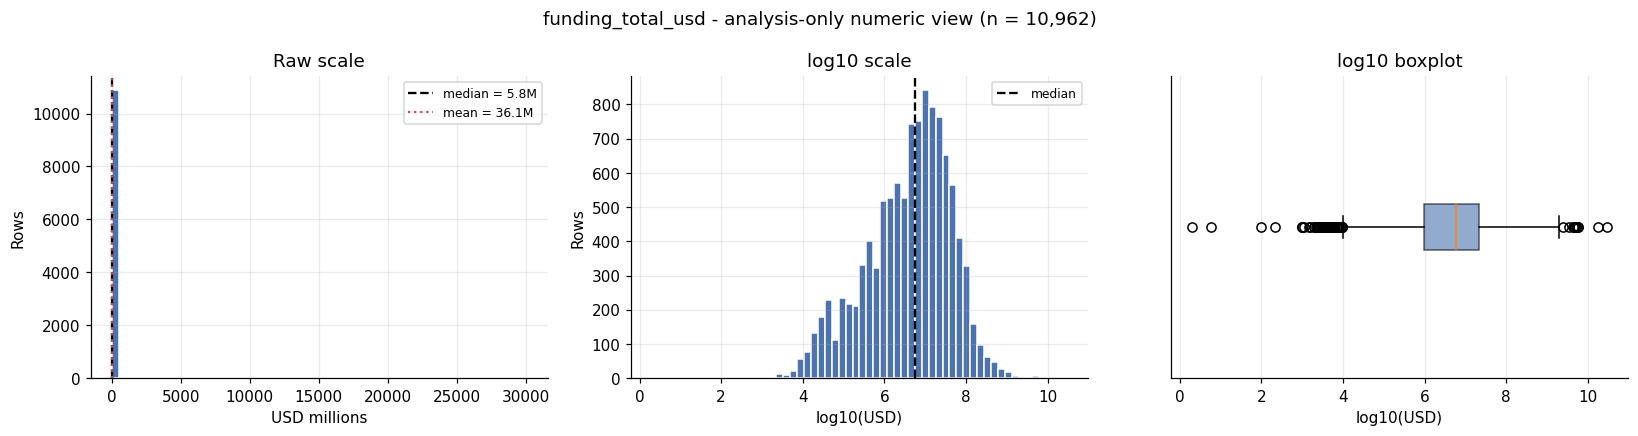

In [15]:
funding_values = funding_usd.dropna()
funding_log = np.log10(funding_values)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(funding_values / 1e6, bins=60, color="#4C72B0", edgecolor="white")
axes[0].axvline(
    funding_values.median() / 1e6,
    color="black",
    linestyle="--",
    label=f"median = {funding_values.median() / 1e6:,.1f}M",
)
axes[0].axvline(
    funding_values.mean() / 1e6,
    color="#C44E52",
    linestyle=":",
    label=f"mean = {funding_values.mean() / 1e6:,.1f}M",
)
axes[0].set_title("Raw scale")
axes[0].set_xlabel("USD millions")
axes[0].set_ylabel("Rows")
axes[0].legend(fontsize=8)

axes[1].hist(funding_log, bins=60, color="#4C72B0", edgecolor="white")
axes[1].axvline(np.log10(funding_values.median()), color="black", linestyle="--", label="median")
axes[1].set_title("log10 scale")
axes[1].set_xlabel("log10(USD)")
axes[1].set_ylabel("Rows")
axes[1].legend(fontsize=8)

axes[2].boxplot(
    funding_log,
    orientation="horizontal",
    patch_artist=True,
    boxprops={"facecolor": "#4C72B0", "alpha": 0.6},
)
axes[2].set_title("log10 boxplot")
axes[2].set_xlabel("log10(USD)")
axes[2].set_yticks([])

fig.suptitle(f"funding_total_usd - analysis-only numeric view (n = {funding_values.size:,})")
plt.tight_layout()
plt.show()


### 11.3 `funding_rounds`

`funding_rounds` is a discrete count with no missing values. It is strongly
right-skewed: most startups have one or two rounds, while a small tail reaches 18.
The IQR is only one round, so the 1.5 x IQR fence flags a non-trivial share of
high counts; those are genuine large financing histories, not data errors. The
median (one round) is a better summary than the mean, which is pulled upward by
the tail. The variable is a forbidden model input, so it is described here only.

There are no zero-round startups: the labelled sample is effectively conditioned
on having at least one recorded funding round. This is a sample-selection caveat,
not a model-input issue.


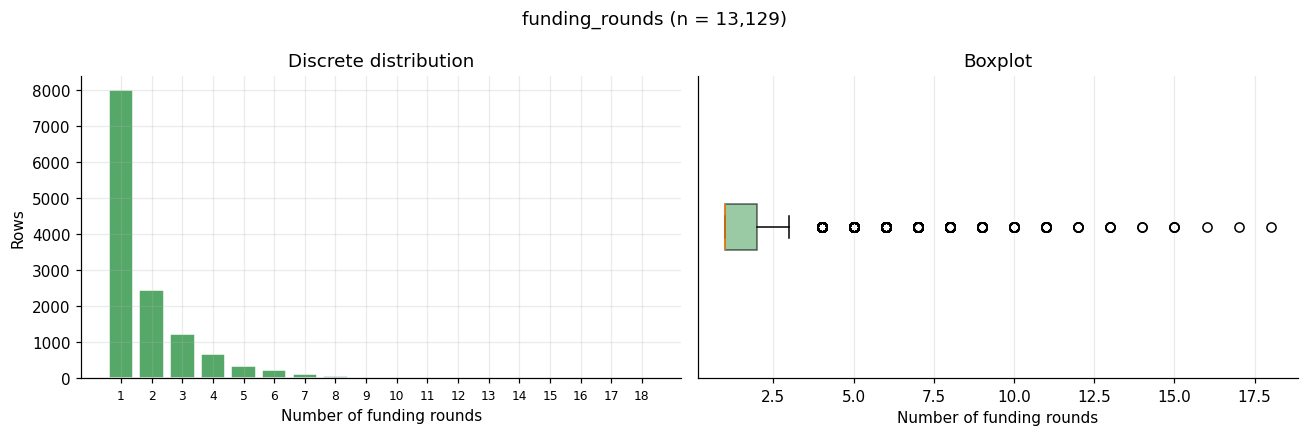

In [16]:
rounds = dataset["funding_rounds"]
round_counts = rounds.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(round_counts.index, round_counts.values, color="#55A868", edgecolor="white")
axes[0].set_title("Discrete distribution")
axes[0].set_xlabel("Number of funding rounds")
axes[0].set_ylabel("Rows")
axes[0].set_xticks(range(1, int(rounds.max()) + 1))
axes[0].tick_params(axis="x", labelsize=8)

axes[1].boxplot(
    rounds.dropna(),
    orientation="horizontal",
    patch_artist=True,
    boxprops={"facecolor": "#55A868", "alpha": 0.6},
)
axes[1].set_title("Boxplot")
axes[1].set_xlabel("Number of funding rounds")
axes[1].set_yticks([])

fig.suptitle(f"funding_rounds (n = {rounds.notna().sum():,})")
plt.tight_layout()
plt.show()


### 11.4 `founding_year`

`founding_year` is the only numerical model input. It is left-skewed: the mass is
concentrated in the 2000s and early 2010s, with a thin tail of much older firms.
The median is 2007 and the IQR is narrow, so the 1.5 x IQR rule flags old firms as
low outliers. The maximum is 2016 and only one row is dated 2016; no valid founding
date falls between 2017 and 2026, and the latest first-funding date is 2015-12-04.
This is consistent with a data snapshot taken around 2016, not a natural limit of the
variable. More than a quarter of the rows have no usable founding year, so
all statements about this variable apply to the observed subset only; the missing
values are not imputed here.


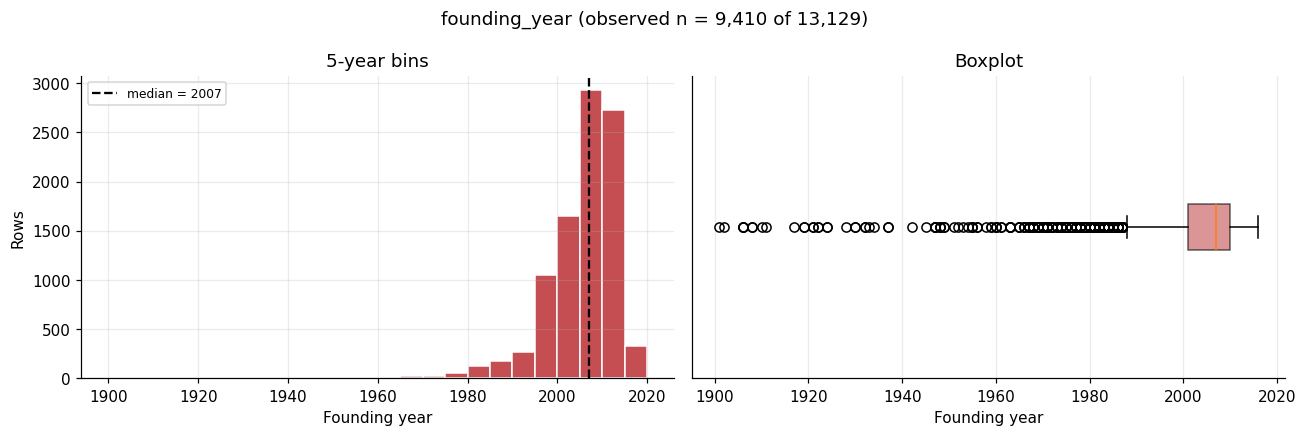

In [17]:
years = dataset["founding_year"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(years, bins=np.arange(1900, 2021, 5), color="#C44E52", edgecolor="white")
axes[0].axvline(years.median(), color="black", linestyle="--", label=f"median = {years.median():.0f}")
axes[0].set_title("5-year bins")
axes[0].set_xlabel("Founding year")
axes[0].set_ylabel("Rows")
axes[0].legend(fontsize=8)

axes[1].boxplot(
    years,
    orientation="horizontal",
    patch_artist=True,
    boxprops={"facecolor": "#C44E52", "alpha": 0.6},
)
axes[1].set_title("Boxplot")
axes[1].set_xlabel("Founding year")
axes[1].set_yticks([])

fig.suptitle(f"founding_year (observed n = {years.size:,} of {len(dataset):,})")
plt.tight_layout()
plt.show()


## 12. Categorical features

Three categorical variables are profiled: `country_code`, `city` and
`primary_category`. For each, the summary reports non-missing count, missingness,
cardinality, top-level concentration and the number/share of rare levels (fewer
than 30 rows). Rare levels are not merged here: the chi-square test in the next
stage will need an explicit grouping rule.

**Denominators.** In the categorical summary and top-category tables, all shares
use non-missing rows as the denominator; `missing (%)` is the exception and uses
all 13,129 rows. This is why the top-10 share of `primary_category` here is larger
than the baseline's "of all rows" coverage: both are correct, but the denominators
differ.


In [18]:
def categorical_profile(series, label):
    counts = series.value_counts()
    total = int(counts.sum())
    rare = counts[counts < 30]
    return pd.Series(
        {
            "non-missing": total,
            "missing": int(series.isna().sum()),
            "missing (%)": round(100 * series.isna().mean(), 1),
            "distinct levels": int(series.nunique()),
            "top level": counts.index[0],
            "top count": int(counts.iloc[0]),
            "top share (%)": round(100 * counts.iloc[0] / total, 1),
            "top 5 share (%)": round(100 * counts.head(5).sum() / total, 1),
            "top 10 share (%)": round(100 * counts.head(10).sum() / total, 1),
            "levels <30 rows": int(len(rare)),
            "rows in levels <30 (%)": round(100 * rare.sum() / total, 1),
            "singleton levels": int((counts == 1).sum()),
        },
        name=label,
    )

categorical_profiles = pd.concat(
    [
        categorical_profile(dataset["country_code"], "country_code"),
        categorical_profile(dataset["city"], "city"),
        categorical_profile(dataset["primary_category"], "primary_category"),
    ],
    axis=1,
).T
display(categorical_profiles)


def top_categories(series, n=15):
    counts = series.value_counts()
    total = int(counts.sum())
    table = counts.head(n).to_frame("rows")
    table.index.name = series.name
    table["share of non-missing (%)"] = (100 * table["rows"] / total).round(1)
    table["cumulative (%)"] = table["share of non-missing (%)"].cumsum().round(1)
    return table


def plot_top_categories(series, title, color, n=15, figsize=(9, 5)):
    counts = series.value_counts().head(n).sort_values()
    fig, ax = plt.subplots(figsize=figsize)
    ax.barh(counts.index, counts.values, color=color, edgecolor="white")
    ax.set_title(title)
    ax.set_xlabel("Rows (non-missing)")
    ax.set_ylabel("")
    for position, value in enumerate(counts.values):
        ax.text(value, position, f" {value:,}", va="center", fontsize=8)
    ax.margins(x=0.15)
    plt.tight_layout()
    plt.show()


,non-missing,missing,missing (%),distinct levels,top level,top count,top share (%),top 5 share (%),top 10 share (%),levels <30 rows,rows in levels <30 (%),singleton levels
country_code,11138,1991,15.2,83,USA,8172,73.4,85.0,91.0,62,3.5,21
city,10996,2133,16.2,1671,San Francisco,855,7.8,19.7,27.3,1611,44.5,919
primary_category,12052,1077,8.2,503,Biotechnology,1079,9.0,31.4,44.9,438,20.0,123


### 12.1 `country_code`

`country_code` is concentrated: one country dominates the labelled set, and the
top few levels cover most non-missing rows. The remaining levels are numerous but
individually small, including many singletons. This is a case where grouping rare
countries is likely necessary before any test that assumes adequate expected
counts.


,rows,share of non-missing (%),cumulative (%)
country_code,,,
USA,8172,73.4,73.4
GBR,540,4.8,78.2
CAN,395,3.5,81.7
RUS,183,1.6,83.3
FRA,181,1.6,84.9
DEU,181,1.6,86.5
CHN,180,1.6,88.1
IND,129,1.2,89.3
ESP,94,0.8,90.1


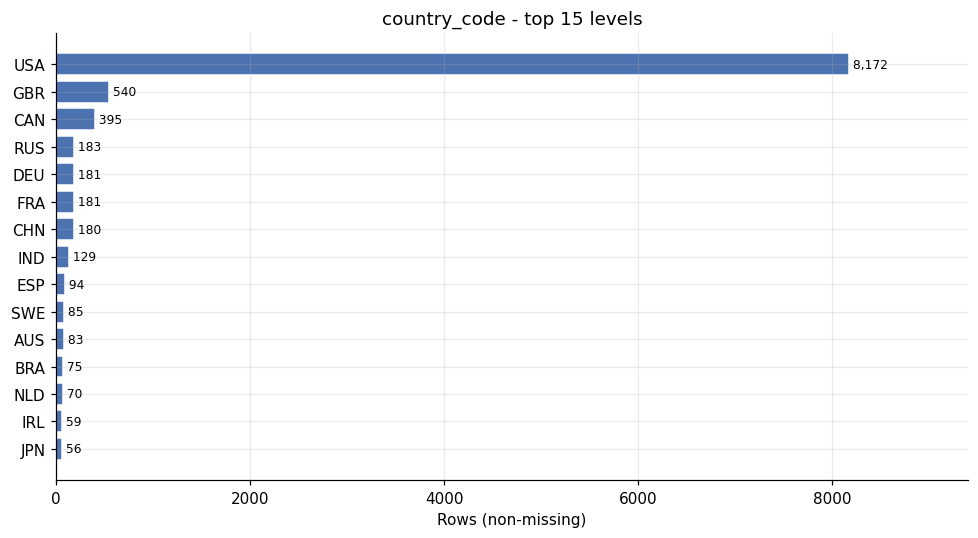

In [19]:
display(top_categories(dataset["country_code"]))
plot_top_categories(
    dataset["country_code"],
    "country_code - top 15 levels",
    "#4C72B0",
)


### 12.2 `city`

`city` is the most fragmented categorical variable: the top cities are well known
startup hubs, but most levels are rare and many appear only once. The top-15 chart
therefore covers only a minority of rows. Any city-level analysis or encoding must
handle this long tail explicitly; the current model pipeline groups rare levels,
and the chi-square test will need a similar rule.


,rows,share of non-missing (%),cumulative (%)
city,,,
San Francisco,855,7.8,7.8
New York,646,5.9,13.7
London,258,2.3,16.0
Palo Alto,207,1.9,17.9
Seattle,198,1.8,19.7
Austin,179,1.6,21.3
Mountain View,179,1.6,22.9
Cambridge,164,1.5,24.4
San Diego,158,1.4,25.8


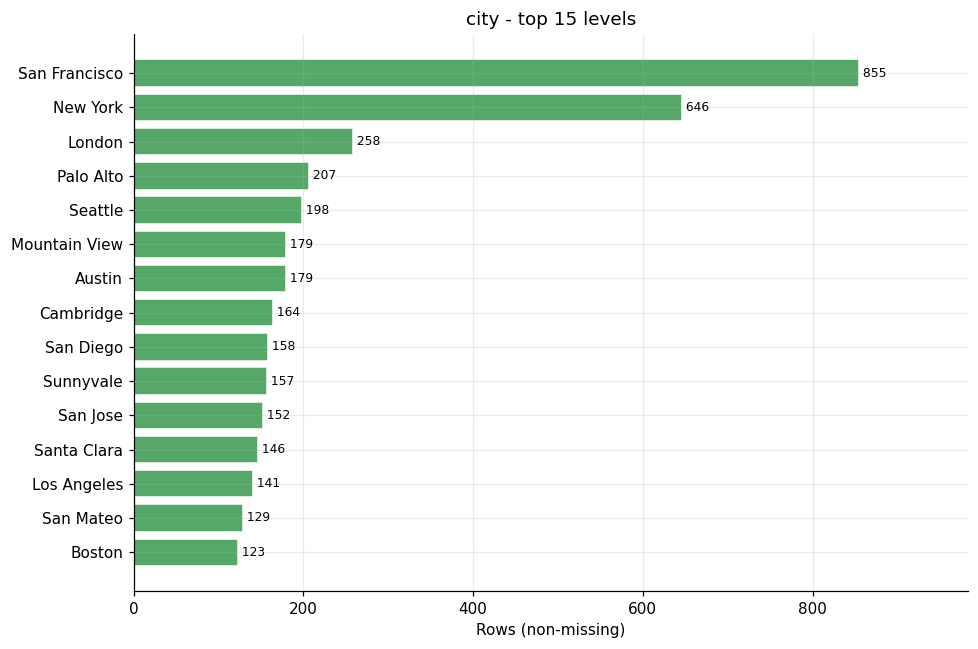

In [20]:
display(top_categories(dataset["city"]))
plot_top_categories(
    dataset["city"],
    "city - top 15 levels",
    "#55A868",
    figsize=(9, 6),
)


### 12.3 `primary_category`

`primary_category` is moderately concentrated: a handful of sectors cover a large
share of rows, but the distribution still has a long tail of small levels. The
baseline audit already reported the cardinality; the table and chart below show
where the mass sits and how much of the data the rare levels represent. This is
the variable planned for the chi-square test, so the rare-level grouping rule is
the key methodological decision.


,rows,share of non-missing (%),cumulative (%)
primary_category,,,
Biotechnology,1079,9.0,9.0
Software,946,7.8,16.8
Curated Web,741,6.1,22.9
Advertising,582,4.8,27.7
E-Commerce,437,3.6,31.3
Mobile,409,3.4,34.7
Enterprise Software,364,3.0,37.7
Games,306,2.5,40.2
Analytics,281,2.3,42.5


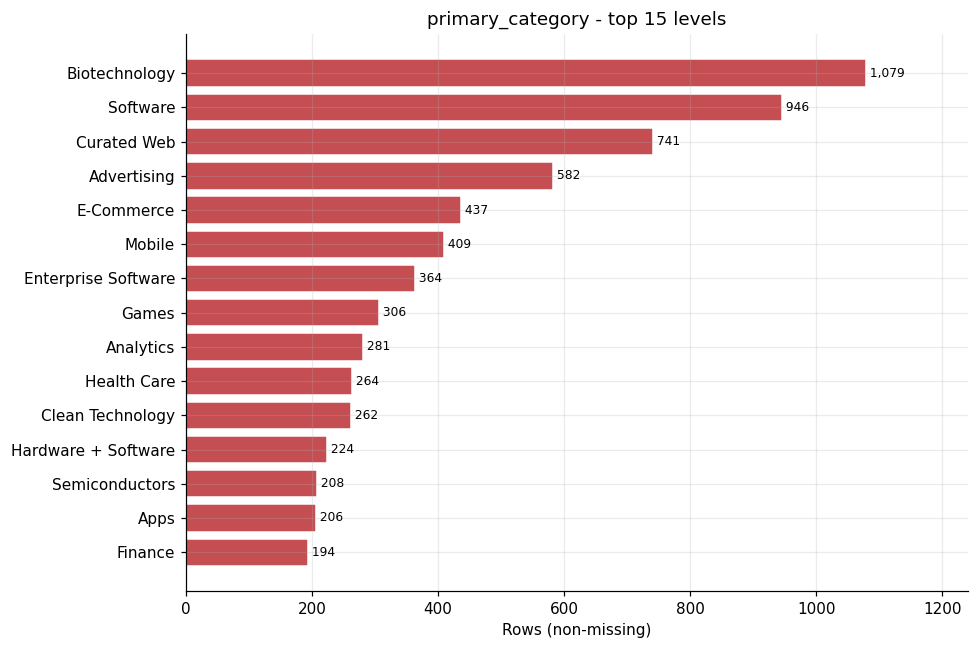

In [21]:
display(top_categories(dataset["primary_category"]))
plot_top_categories(
    dataset["primary_category"],
    "primary_category - top 15 levels",
    "#C44E52",
    figsize=(9, 6),
)


## 13. Key findings for the next stage

- **Funding variables are descriptive only.** `funding_total_usd` and
  `funding_rounds` are in `splitting.FORBIDDEN_FEATURES`; they must not be added
  to the model inputs. Their distributions are still useful for understanding the
  sample and for the report.
- **`funding_total_usd` is heavily right-skewed.** The mean is far above the
  median, the tail reaches tens of billions, and the IQR rule flags a substantial
  minority of high values. Median/IQR and a log10 view are the defensible
  summaries; the 2 USD minimum is a data-quality flag.
- **`funding_rounds` is a discrete right-skewed count.** Most startups have one or
  two rounds; the tail is real financing history, not an error. The absence of
  zero-round startups means the sample is conditioned on having at least one
  recorded round.
- **`founding_year` is left-skewed and incomplete.** The sample is concentrated in
  the 2000s, the maximum is the 2016 snapshot boundary, and more than a quarter of
  rows have no usable year. The Mann-Whitney test will describe the observed
  subset only.
- **Categorical concentration differs sharply.** Country is dominated by one
  level; city is extremely fragmented; primary_category has a moderate head and a
  long rare tail. Rare-level grouping will be required for the chi-square test.
- **No preprocessing was performed.** All transformations above are analysis-only;
  `dataset`, the official feature contract and the preprocessing pipeline are
  unchanged.


## 14. Next step (not part of this deliverable)

1. Chi-square test of independence: `primary_category` (after grouping rare levels)
   vs `target`, with expected-count checks.
2. Mann-Whitney U test: `founding_year` in class 1 vs class 0, with the
   observation-window caveat.
3. Only then, the final figures and the written interpretation for the report.

The Streamlit dashboard (`src/dashboard_eda.py`) already covers descriptives,
missingness, histograms, frequencies, correlations and filters; this notebook
should not duplicate it. It should deliver the analysis and the hypothesis tests.
